## 1. Project Setup and Configuration

Import the required libraries and configure the project directories, dataset path, model settings, and computation device (GPU or CPU). Define the artifact and output directories for storing extracted features, evaluation results, and trained models.

In [20]:
from pathlib import Path
import hashlib
import json
import warnings

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from PIL import Image
from tqdm.auto import tqdm

from transformers import AutoImageProcessor, AutoModel

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

# Project paths
PROJECT_DIR = Path(r"C:\Projects\adInsightPrediction")
CSV_PATH = PROJECT_DIR / "data" / "ad_labels.csv"

ARTIFACT_DIR = PROJECT_DIR / "artifacts"
FEATURE_CACHE_DIR = ARTIFACT_DIR / "dinov2_large_features"
RESULTS_DIR = PROJECT_DIR / "outputs" / "dinov2_large"

FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Model configuration
MODEL_NAME = "facebook/dinov2-large"
FRAME_COUNT = 4
RANDOM_STATE = 42

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Project:", PROJECT_DIR)
print("CSV:", CSV_PATH)
print("Device:", DEVICE)
print("Model:", MODEL_NAME)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Feature extraction will run on CPU.")

Project: C:\Projects\adInsightPrediction
CSV: C:\Projects\adInsightPrediction\data\ad_labels.csv
Device: cuda
Model: facebook/dinov2-large
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 2. Load and Validate the Dataset

Load the advertisement labels CSV and clean the column names. Validate asset IDs, brand names, file paths, and the six target attributes. Ensure all labels are numeric and fall within the range of 0 to 1, and verify that all image and video files exist and have supported formats.

In [21]:
assert CSV_PATH.exists(), f"CSV not found: {CSV_PATH}"

df = pd.read_csv(CSV_PATH)

# Clean headers, including accidental Markdown asterisks
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace("*", "", regex=False)
)

TARGET_COLS = [
    "innovation",
    "premium",
    "minimalism",
    "excitement",
    "social_orientation",
    "aspiration",
]

REQUIRED_COLS = [
    "asset_id",
    "brand",
    "file_path",
    *TARGET_COLS,
]

missing_cols = set(REQUIRED_COLS) - set(df.columns)
if missing_cols:
    raise ValueError(f"Missing CSV columns: {sorted(missing_cols)}")

# Standardize identifiers and text
df["asset_id"] = df["asset_id"].astype(str).str.strip()
df["brand"] = df["brand"].astype(str).str.strip()
df["file_path"] = df["file_path"].astype(str).str.strip()

if df["asset_id"].duplicated().any():
    duplicates = df.loc[df["asset_id"].duplicated(), "asset_id"].tolist()
    raise ValueError(f"Duplicate asset IDs: {duplicates}")

# Convert labels to numeric
for col in TARGET_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[TARGET_COLS].isna().any().any():
    raise ValueError("Some target labels are missing or non-numeric.")

if not df[TARGET_COLS].apply(
    lambda col: col.between(0, 1).all()
).all():
    raise ValueError("All six labels must be between 0 and 1.")

# Resolve absolute and relative file paths
def resolve_asset_path(path_string):
    raw_path = Path(path_string)

    candidates = [
        raw_path,
        PROJECT_DIR / raw_path,
        PROJECT_DIR / "data" / raw_path,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()

    return None

df["resolved_path"] = df["file_path"].apply(resolve_asset_path)

missing_files = df[df["resolved_path"].isna()]

if not missing_files.empty:
    print(missing_files[["asset_id", "file_path"]].to_string(index=False))
    raise FileNotFoundError(
        f"{len(missing_files)} asset files could not be found. "
        "Fix their paths before proceeding."
    )

# Identify media types
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
VIDEO_EXTENSIONS = {".mp4", ".mov", ".avi", ".mkv", ".webm"}

def get_media_type(path):
    suffix = Path(path).suffix.lower()

    if suffix in IMAGE_EXTENSIONS:
        return "image"
    if suffix in VIDEO_EXTENSIONS:
        return "video"

    return "unsupported"

df["media_type"] = df["resolved_path"].apply(get_media_type)

if (df["media_type"] == "unsupported").any():
    bad = df.loc[
        df["media_type"] == "unsupported",
        ["asset_id", "resolved_path"]
    ]
    raise ValueError(f"Unsupported media files:\n{bad}")

print("Dataset shape:", df.shape)
print("Number of assets:", len(df))
print("\nBrands:")
print(df["brand"].value_counts())
print("\nMedia types:")
print(df["media_type"].value_counts())
print("\nTarget summary:")
display(df[TARGET_COLS].describe().round(3))

Dataset shape: (65, 11)
Number of assets: 65

Brands:
brand
Apple        13
BMW          13
CocaCola     13
McDonalds    13
Nike         13
Name: count, dtype: int64

Media types:
media_type
image    50
video    15
Name: count, dtype: int64

Target summary:


,innovation,premium,minimalism,excitement,social_orientation,aspiration
count,65.000,65.000,65.000,65.000,65.000,65.000
mean,0.406,0.446,0.327,0.668,0.322,0.479
std,0.352,0.307,0.306,0.223,0.383,0.237
min,0.020,0.020,0.020,0.180,0.010,0.100
25%,0.060,0.150,0.080,0.550,0.020,0.250
50%,0.240,0.400,0.190,0.710,0.100,0.430
75%,0.760,0.730,0.520,0.850,0.850,0.690
max,0.940,0.950,0.980,0.980,0.980,0.960


## 3. Exploratory Data Analysis (EDA)

Examine the dataset size, brand distribution, media types, and descriptive statistics of the six attributes. Visualize the distribution of attribute scores and compare their average values across brands to understand the dataset before model development.

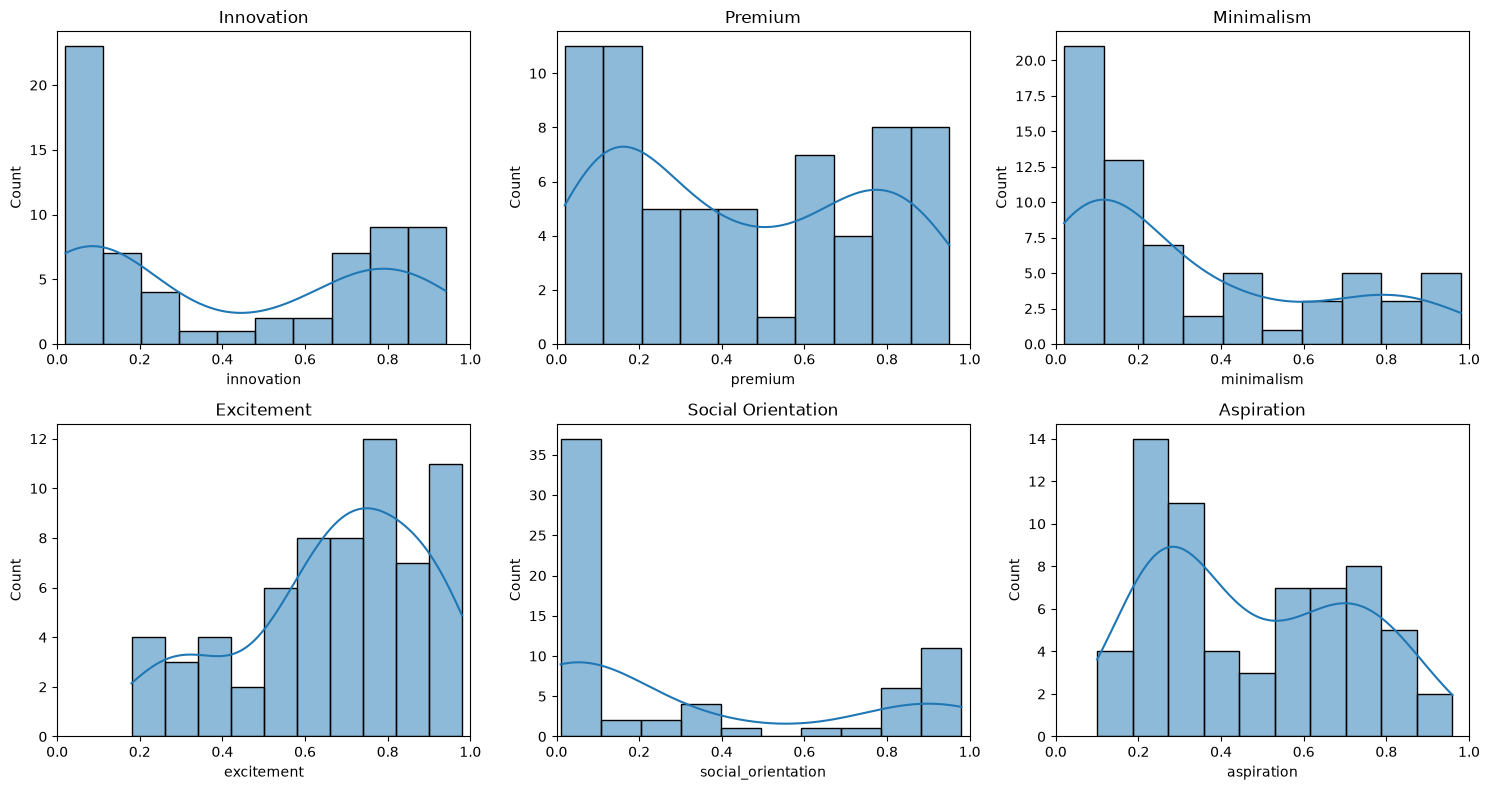

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, ax in zip(TARGET_COLS, axes.flatten()):
    sns.histplot(
        data=df,
        x=col,
        bins=10,
        kde=True,
        ax=ax
    )
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

In [23]:
display(
    df.groupby("brand")[TARGET_COLS]
      .mean()
      .round(3)
)

,innovation,premium,minimalism,excitement,social_orientation,aspiration
brand,,,,,,
Apple,0.766,0.655,0.660,0.559,0.136,0.436
BMW,0.765,0.870,0.197,0.636,0.102,0.558
CocaCola,0.167,0.169,0.238,0.818,0.614,0.428
McDonalds,0.087,0.224,0.224,0.698,0.435,0.283
Nike,0.245,0.312,0.315,0.629,0.322,0.688


## 4. Train, Validation, and Test Split

Split the dataset into training (70%), validation (15%), and test (15%) subsets while maintaining brand representation. Save the split assignments to support reproducibility and fair model comparisons. Keep each advertisement entirely within one split to prevent data leakage.

In [24]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df["brand"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["brand"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name} brand distribution:")
    print(split_df["brand"].value_counts().sort_index())

# Save the split assignments for reproducibility
split_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test"),
], ignore_index=True)

split_df[["asset_id", "brand", "split"]].to_csv(
    RESULTS_DIR / "split_assignments.csv",
    index=False
)

Train: 45
Validation: 10
Test: 10

Train brand distribution:
brand
Apple        9
BMW          9
CocaCola     9
McDonalds    9
Nike         9
Name: count, dtype: int64

Validation brand distribution:
brand
Apple        2
BMW          2
CocaCola     2
McDonalds    2
Nike         2
Name: count, dtype: int64

Test brand distribution:
brand
Apple        2
BMW          2
CocaCola     2
McDonalds    2
Nike         2
Name: count, dtype: int64


## 5. Load the DINOv2 ViT-L/14 Encoder

Load the pretrained DINOv2 ViT-L/14 image processor and encoder. Keep the encoder frozen and use it as a feature extractor rather than fine-tuning it on the limited labeled dataset. The model generates a 1024-dimensional global embedding for each image or video frame.

In [25]:
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME)

encoder = encoder.to(DEVICE)
encoder.eval()

FEATURE_DIM = encoder.config.hidden_size

print("Feature dimension:", FEATURE_DIM)
assert FEATURE_DIM == 1024

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

Feature dimension: 1024


## 6. Extract Image Features

Preprocess each image using the DINOv2 image processor and extract its CLS-token embedding. Convert the embedding into a 1024-dimensional numerical feature vector that represents the advertisement's visual characteristics.

In [26]:
@torch.inference_mode()
def extract_frame_feature(image):
    image = image.convert("RGB")

    inputs = processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    # Mixed precision on CUDA can reduce memory use.
    if DEVICE == "cuda":
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = encoder(**inputs)
    else:
        outputs = encoder(**inputs)

    # CLS token: one global embedding per frame
    feature = outputs.last_hidden_state[:, 0, :]

    return (
        feature.squeeze(0)
        .float()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

## 7. Extract Video Features

Sample four frames uniformly across each video, extract a DINOv2 embedding for every sampled frame, and average the embeddings into a single 1024-dimensional representation. This provides one feature vector per video while keeping the computational requirements manageable.

In [27]:
def load_video_frames(video_path, frame_count=FRAME_COUNT):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError(f"Video has no readable frames: {video_path}")

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num=min(frame_count, total_frames),
        dtype=int
    )

    frames = []

    for frame_idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        success, frame = cap.read()

        if success:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(Image.fromarray(frame_rgb))

    cap.release()

    if not frames:
        raise ValueError(f"No frames could be decoded: {video_path}")

    return frames


def extract_asset_feature(row):
    asset_path = Path(row["resolved_path"])
    media_type = row["media_type"]

    if media_type == "image":
        with Image.open(asset_path) as image:
            return extract_frame_feature(image)

    if media_type == "video":
        frames = load_video_frames(asset_path)

        frame_features = [
            extract_frame_feature(frame)
            for frame in frames
        ]

        # One embedding per video asset
        return np.mean(
            np.stack(frame_features, axis=0),
            axis=0
        ).astype(np.float32)

    raise ValueError(f"Unsupported media type: {media_type}")

## 8. Cache Extracted Features

Save the extracted feature vectors as NumPy files to avoid repeatedly processing the same assets. Reuse cached features during subsequent notebook runs, and validate their dimensions and numerical values before model training.

In [28]:
def cache_path_for_asset(asset_id):
    safe_id = hashlib.sha256(
        str(asset_id).encode("utf-8")
    ).hexdigest()[:24]

    return FEATURE_CACHE_DIR / f"{safe_id}.npy"


feature_by_id = {}

for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Extracting DINOv2 Large features"
):
    asset_id = row["asset_id"]
    cache_path = cache_path_for_asset(asset_id)

    if cache_path.exists():
        feature = np.load(cache_path)
    else:
        feature = extract_asset_feature(row)
        np.save(cache_path, feature)

    if feature.shape != (FEATURE_DIM,):
        raise ValueError(
            f"Unexpected feature shape for {asset_id}: {feature.shape}"
        )

    if not np.isfinite(feature).all():
        raise ValueError(f"Non-finite features found for {asset_id}")

    feature_by_id[asset_id] = feature

print("Assets with features:", len(feature_by_id))

Extracting DINOv2 Large features:   0%|          | 0/65 [00:00<?, ?it/s]

Assets with features: 65


## 9. Prepare Feature Matrices and Target Labels

Construct feature matrices for the training, validation, and test sets using the cached DINOv2 embeddings. Extract the six target attributes separately to prepare the inputs and labels required for regression.

In [29]:
def build_feature_matrix(split_df):
    return np.stack([
        feature_by_id[asset_id]
        for asset_id in split_df["asset_id"]
    ]).astype(np.float32)


X_train = build_feature_matrix(train_df)
X_val = build_feature_matrix(val_df)
X_test = build_feature_matrix(test_df)

y_train = train_df[TARGET_COLS].to_numpy(dtype=np.float32)
y_val = val_df[TARGET_COLS].to_numpy(dtype=np.float32)
y_test = test_df[TARGET_COLS].to_numpy(dtype=np.float32)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("Number of targets:", len(TARGET_COLS))

X_train: (45, 1024)
X_val: (10, 1024)
X_test: (10, 1024)
Number of targets: 6


## 10. Train and Tune Six Independent Ridge Regressors

Train six separate Ridge regression models, one for each target attribute: innovation, premium, minimalism, excitement, social orientation, and aspiration. Standardize the extracted features and use three-fold, brand-stratified cross-validation with GridSearchCV to select the optimal regularization parameter (alpha) independently for each attribute.

In [30]:
ALPHAS = [0.1, 1, 10, 30, 100, 300, 1000, 3000]

# Three-fold CV using only the training data.
# Reuse identical fold assignments for all six targets.
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_splits = list(
    cv.split(X_train, train_df["brand"])
)

best_models = {}
best_alphas = {}
validation_predictions = {}

tuning_results = []

for i, target in enumerate(TARGET_COLS):
    print(f"\nTuning: {target}")

    y_target = y_train[:, i]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge())
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"ridge__alpha": ALPHAS},
        scoring="neg_mean_absolute_error",
        cv=cv_splits,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_target)

    best_models[target] = search.best_estimator_
    best_alphas[target] = search.best_params_["ridge__alpha"]

    # Validation predictions come from models trained on train only
    val_pred = search.best_estimator_.predict(X_val)
    validation_predictions[target] = np.clip(val_pred, 0, 1)

    tuning_results.append({
        "attribute": target,
        "best_alpha": best_alphas[target],
        "best_cv_MAE": -search.best_score_,
        "validation_MAE": mean_absolute_error(
            y_val[:, i], val_pred
        ),
    })

    print("Best alpha:", best_alphas[target])
    print("CV MAE:", round(-search.best_score_, 4))
    print(
        "Validation MAE:",
        round(mean_absolute_error(y_val[:, i], val_pred), 4)
    )

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.round(4))

tuning_df.to_csv(
    RESULTS_DIR / "ridge_tuning_results.csv",
    index=False
)


Tuning: innovation


Best alpha: 0.1
CV MAE: 0.1709
Validation MAE: 0.1303

Tuning: premium
Best alpha: 300
CV MAE: 0.1611
Validation MAE: 0.1765

Tuning: minimalism
Best alpha: 300
CV MAE: 0.198
Validation MAE: 0.1801

Tuning: excitement
Best alpha: 1000
CV MAE: 0.168
Validation MAE: 0.1873

Tuning: social_orientation
Best alpha: 30
CV MAE: 0.2038
Validation MAE: 0.1893

Tuning: aspiration
Best alpha: 100
CV MAE: 0.1556
Validation MAE: 0.1336


,attribute,best_alpha,best_cv_MAE,validation_MAE
0,innovation,0.1,0.1709,0.1303
1,premium,300.0,0.1611,0.1765
2,minimalism,300.0,0.1980,0.1801
3,excitement,1000.0,0.1680,0.1873
4,social_orientation,30.0,0.2038,0.1893
5,aspiration,100.0,0.1556,0.1336


## 11. Validation Set Evaluation

Evaluate the tuned Ridge regressors on the validation set using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². Use these results to inspect model performance before final training and to guide subsequent model improvements.

In [31]:
val_rows = []

for i, target in enumerate(TARGET_COLS):
    y_true = y_val[:, i]
    y_pred = validation_predictions[target]

    val_rows.append({
        "attribute": target,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    })

validation_metrics = pd.DataFrame(val_rows)

display(validation_metrics.round(4))

validation_metrics.to_csv(
    RESULTS_DIR / "validation_metrics.csv",
    index=False
)

,attribute,MAE,RMSE,R2
0,innovation,0.1303,0.1696,0.7481
1,premium,0.1765,0.2153,0.4998
2,minimalism,0.1801,0.2122,0.4913
3,excitement,0.1873,0.2276,0.2381
4,social_orientation,0.1893,0.2750,0.5744
5,aspiration,0.1336,0.1528,0.6124


## 12. Train the Final Models

Combine the training and validation subsets and retrain each Ridge regressor using its selected alpha value. This allows the final models to learn from more labeled advertisements while preserving the held-out test set for final evaluation.

In [32]:
X_trainval = np.vstack([X_train, X_val])
y_trainval = np.vstack([y_train, y_val])

final_models = {}

for i, target in enumerate(TARGET_COLS):
    final_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=best_alphas[target]))
    ])

    final_model.fit(X_trainval, y_trainval[:, i])
    final_models[target] = final_model

print("All six final regressors trained.")

All six final regressors trained.


## 13. Final Test Evaluation

Evaluate the six final regressors on the untouched test set using MAE, RMSE, and R². Compare errors across attributes to identify which visual characteristics are predicted more accurately and which require further improvement.

In [33]:
test_predictions = np.column_stack([
    final_models[target].predict(X_test)
    for target in TARGET_COLS
])

# Scores are defined on a 0–1 scale.
test_predictions = np.clip(test_predictions, 0, 1)

test_rows = []

for i, target in enumerate(TARGET_COLS):
    y_true = y_test[:, i]
    y_pred = test_predictions[:, i]

    test_rows.append({
        "attribute": target,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "best_alpha": best_alphas[target]
    })

test_metrics = pd.DataFrame(test_rows)

display(test_metrics.round(4))

test_metrics.to_csv(
    RESULTS_DIR / "test_metrics.csv",
    index=False
)

,attribute,MAE,RMSE,R2,best_alpha
0,innovation,0.1798,0.2260,0.6334,0.1
1,premium,0.1719,0.2256,0.5438,300.0
2,minimalism,0.1793,0.2269,0.3318,300.0
3,excitement,0.1359,0.1602,0.2392,1000.0
4,social_orientation,0.1946,0.2336,0.6655,30.0
5,aspiration,0.1605,0.1868,0.2013,100.0


## 14. Prediction Analysis and Error Inspection

Compare the actual and predicted scores for each test advertisement. Calculate absolute errors and visualize actual-versus-predicted values to identify systematic overprediction, underprediction, and advertisements with large prediction errors.

In [34]:
prediction_df = test_df[
    ["asset_id", "brand", "media_type", "file_path"]
].copy()

for i, target in enumerate(TARGET_COLS):
    prediction_df[f"{target}_actual"] = y_test[:, i]
    prediction_df[f"{target}_predicted"] = test_predictions[:, i]
    prediction_df[f"{target}_abs_error"] = np.abs(
        y_test[:, i] - test_predictions[:, i]
    )

display(prediction_df.round(3))

prediction_df.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

,asset_id,brand,media_type,file_path,innovation_actual,innovation_predicted,innovation_abs_error,premium_actual,premium_predicted,premium_abs_error,...,minimalism_abs_error,excitement_actual,excitement_predicted,excitement_abs_error,social_orientation_actual,social_orientation_predicted,social_orientation_abs_error,aspiration_actual,aspiration_predicted,aspiration_abs_error
0,COC_IMG_006,CocaCola,image,C:\Projects\adInsightPrediction\data\coke\c6.jpg,0.09,0.032,0.058,0.10,0.110,0.010,...,0.120,0.89,0.795,0.095,0.94,0.618,0.322,0.67,0.344,0.326
1,BMW_IMG_003,BMW,image,C:\Projects\adInsightPrediction\data\bmw\b3.jpg,0.82,0.739,0.081,0.88,0.837,0.043,...,0.088,0.71,0.647,0.063,0.02,0.201,0.181,0.75,0.651,0.099
2,MCD_VID_002,McDonalds,video,C:\Projects\adInsightPrediction\data\mcd\mv2.mp4,0.45,0.357,0.093,0.12,0.446,0.326,...,0.174,0.80,0.701,0.099,0.87,0.589,0.281,0.76,0.568,0.192
3,MCD_IMG_007,McDonalds,image,C:\Projects\adInsightPrediction\data\mcd\m7.jpg,0.04,0.128,0.088,0.23,0.419,0.189,...,0.117,0.54,0.705,0.165,0.02,0.079,0.059,0.22,0.214,0.006
4,NIK_IMG_002,Nike,image,C:\Projects\adInsightPrediction\data\nike\n2.jpg,0.02,0.171,0.151,0.34,0.361,0.021,...,0.046,0.92,0.797,0.123,0.87,0.536,0.334,0.87,0.731,0.139
5,NIK_IMG_009,Nike,image,C:\Projects\adInsightPrediction\data\nike\n9.jpg,0.03,0.340,0.310,0.04,0.454,0.414,...,0.264,0.75,0.639,0.111,0.10,0.278,0.178,0.56,0.690,0.130
6,BMW_IMG_006,BMW,image,C:\Projects\adInsightPrediction\data\bmw\b6.jpg,0.76,0.802,0.042,0.83,0.846,0.016,...,0.143,0.57,0.598,0.028,0.02,0.000,0.020,0.34,0.582,0.242
7,APP_VID_001,Apple,video,C:\Projects\adInsightPrediction\data\apple\av1...,0.90,0.553,0.347,0.79,0.559,0.231,...,0.035,0.33,0.631,0.301,0.35,0.250,0.100,0.45,0.545,0.095
8,COC_VID_002,CocaCola,video,C:\Projects\adInsightPrediction\data\coke\cv2.mp4,0.88,0.414,0.466,0.12,0.476,0.356,...,0.280,0.93,0.649,0.281,0.87,0.458,0.412,0.56,0.643,0.083
9,APP_IMG_008,Apple,image,C:\Projects\adInsightPrediction\data\apple\a8.jpg,0.80,0.962,0.162,0.78,0.666,0.114,...,0.526,0.61,0.702,0.092,0.01,0.069,0.059,0.28,0.571,0.291


## 15. Save the Trained Model Bundle

Save the six trained Ridge regressors, their selected alpha values, target names, and feature-extraction configuration in a single Joblib bundle. This enables the trained models to be reused for inference without repeating model training.

In [35]:
MODEL_BUNDLE_PATH = RESULTS_DIR / "six_attribute_ridge_models.joblib"

model_bundle = {
    "models": final_models,
    "targets": TARGET_COLS,
    "best_alphas": best_alphas,
    "model_name": MODEL_NAME,
    "feature_dim": FEATURE_DIM,
    "frame_count": FRAME_COUNT,
    "random_state": RANDOM_STATE,
    "feature_method": "CLS token; uniformly sampled video frames averaged",
}

joblib.dump(model_bundle, MODEL_BUNDLE_PATH)

print("Saved model bundle:", MODEL_BUNDLE_PATH)
print("Saved results to:", RESULTS_DIR)

Saved model bundle: C:\Projects\adInsightPrediction\outputs\dinov2_large\six_attribute_ridge_models.joblib
Saved results to: C:\Projects\adInsightPrediction\outputs\dinov2_large


## 16. Predict Attributes for New Advertisements

Create an inference function that accepts a new image or video, extracts its features using the same frozen DINOv2 ViT-L/14 encoder, and generates predictions from the six trained Ridge regressors. Return the predicted scores in a structured table, with each attribute represented on the original 0–1 scale.

In [36]:
def predict_advertisement(file_path):
    path = Path(file_path)

    if not path.is_file():
        raise FileNotFoundError(f"Asset not found: {path}")

    media_type = get_media_type(path)

    if media_type == "image":
        with Image.open(path) as image:
            features = extract_frame_feature(image)

    elif media_type == "video":
        frames = load_video_frames(path, FRAME_COUNT)

        frame_features = [
            extract_frame_feature(frame)
            for frame in frames
        ]

        features = np.mean(
            np.stack(frame_features, axis=0),
            axis=0
        ).astype(np.float32)

    else:
        raise ValueError(f"Unsupported media type: {path.suffix}")

    if features.shape != (FEATURE_DIM,):
        raise ValueError(f"Unexpected feature shape: {features.shape}")

    scores = {}

    for target in TARGET_COLS:
        raw_score = final_models[target].predict(
            features.reshape(1, -1)
        )[0]

        scores[target] = float(np.clip(raw_score, 0, 1))

    return pd.DataFrame({
        "attribute": list(scores.keys()),
        "predicted_score": list(scores.values())
    })

## 17. Test on New Advertisements

Run the inference function on previously unseen image and video files. Inspect the six predicted attribute scores to demonstrate how the trained model can analyze new advertisements without requiring additional training.

In [37]:
new_ad_path = r"C:\Projects\adInsightPrediction\data\apple\a1.jpg"

new_predictions = predict_advertisement(new_ad_path)

display(new_predictions.round(3))

,attribute,predicted_score
0,innovation,0.930
1,premium,0.750
2,minimalism,0.377
3,excitement,0.665
4,social_orientation,0.100
5,aspiration,0.430


In [38]:
new_ad_path = r"C:\Projects\adInsightPrediction\data\nike\nv2.mp4"

new_predictions = predict_advertisement(new_ad_path)

display(new_predictions.round(3))

,attribute,predicted_score
0,innovation,0.050
1,premium,0.328
2,minimalism,0.349
3,excitement,0.666
4,social_orientation,0.627
5,aspiration,0.878
